# Mathematical Modeling of HER2+/HER2− Breast Cancer Dynamics
### Phenotypic Plasticity, Competition, and Treatment Sequencing

## Project Overview

This project investigates the dynamics of HER2-positive (HER2+) and HER2-negative (HER2−) breast cancer cell populations using mathematical models and numerical simulations.

The analysis explores how differences in proliferation rates, phenotypic switching, density-dependent growth, and competition influence tumor population dynamics.

The models are progressively extended to investigate the effects of chemotherapy, Notch inhibition, combined treatment, and therapeutic sequencing.

**Main objectives:**
- Compare analytical and numerical solutions of classical population growth models.
- Investigate phenotypic plasticity and the long-term composition of HER2+ and HER2− populations.
- Examine the effects of carrying capacity and interpopulation competition.
- Simulate treatment-induced changes in tumor size and phenotype composition.
- Compare different therapeutic administration schedules.

All simulations are theoretical and intended to explore mathematical mechanisms rather than predict individual clinical outcomes.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# GRAPHS
colN1 = "#11CFA3"
colN2 = "#BD6E07"
colTot = '#212121'


## 1. Model Parameters

The mathematical models describe two interacting breast cancer cell populations:

- **N₁:** HER2-positive (HER2+) cells.
- **N₂:** HER2-negative (HER2−) cells.

The baseline parameters include phenotype-specific proliferation rates, transition rates between phenotypes, carrying capacity, and competition coefficients.

| Parameter | Description |
|---|---|
| K₁ | HER2+ proliferation rate |
| K₂ | HER2− proliferation rate |
| K₁₂ | Transition rate from HER2+ to HER2− |
| K₂₁ | Transition rate from HER2− to HER2+ |
| C | Reference carrying capacity |
| C₁₂ | Competitive effect of HER2− cells on HER2+ cells |
| C₂₁ | Competitive effect of HER2+ cells on HER2− cells |

The same baseline parameter values are used throughout the models where applicable, allowing comparisons between different assumptions about population growth and interactions.

In [2]:
K1 = 1.0     # HER2+ symmetric division rate
K2 = 0.7     # HER2- symmetric division rate
K12 = 0.09   # asymmetric transition rate: HER2+ -> HER2-
K21 = 0.09   # asymmetric transition rate: HER2- -> HER2+
C = 1e6      # reference density scale
C12 = 0.4    # competitive load HER2- imposes on HER2+
C21 = 0.8    # competitive load HER2+ imposes on HER2-

print("Chapter 1. Model Parameters")
print(f"K1={K1}, K2={K2}, K12={K12}, K21={K21}")
print(f"C={C:.0e}, C12={C12}, C21={C21}")

Chapter 1. Model Parameters
K1=1.0, K2=0.7, K12=0.09, K21=0.09
C=1e+06, C12=0.4, C21=0.8



## 2. Continuous Population Growth Models

This section introduces two classical models of population growth: the Malthusian exponential model and the logistic growth model.

### Malthusian Growth
The Malthusian model assumes a constant per-capita proliferation rate and unlimited growth.

The analytical solution is compared with two numerical methods:
- Forward Euler integration.
- Runge–Kutta integration using `solve_ivp` (RK45).

This comparison illustrates the agreement between analytical and numerical solutions.

### Logistic Growth
The logistic model introduces a carrying capacity, limiting population growth as the total number of cells increases.

Unlike exponential growth, the population approaches a finite equilibrium determined by the carrying capacity.

The simulations illustrate the qualitative differences between unrestricted exponential growth and density-dependent logistic growth.

In [3]:
print("\nChapter 2. Continuous growth models")
gamma = 0.25  #cell proliferation rate / biological parameter
N0 = 1        #initial number of cells
#interval 0 <= t <= 20
t0 = 0        #initial time
tf = 20       #ending time
dt = 0.1      #time step for the Forward Euler method

#time vector: sequence of values, including the final time
t_euler = np.arange(t0, tf+dt, dt)
#analytical solution -> calculate the exact population for every temporal value in t_euler
N_exact = N0 * np.exp(gamma * t_euler)

# Forward Euler method
N_euler = np.zeros(len(t_euler))
N_euler[0] = N0
for i in range(len(t_euler) - 1): #the loop stops at the second-to-last element to avoid exceeding the array bounds
    N_euler[i + 1] = N_euler[i] + dt * gamma * N_euler[i]

def malthus_model(t, N):
    return gamma * N
#solve_ivp: to numerically integrate ODE systems and obtain the numerical simulated trajectories over time
sol_malthus = solve_ivp(malthus_model, (t0, tf), [N0], t_eval = t_euler, method="RK45")

# One-population logistic growth model - carrying capacity used only for the introductory logistic model
K_logistic = 150
def logistic_growth_model(t, N):
    dN_dt = gamma * N * (1-N/K_logistic)
    return dN_dt
sol_logistic_single = solve_ivp(logistic_growth_model, (t0, tf), [N0], t_eval=t_euler, method="RK45")

print(f"\nFinal population values at t = {tf:.0f}")
print(f"Analytical solution = {N_exact[-1]:.3f}")
print(f"Forward Euler = {N_euler[-1]:.3f}")
print(f"RK45 = {sol_malthus.y[0, -1]:.3f}")

print("\nSingle-population logistic model")
print(f"RK45 = {sol_logistic_single.y[0, -1]:.3f}")
print(f"Carrying capacity K = {K_logistic:.3f}")


Chapter 2. Continuous growth models

Final population values at t = 20
Analytical solution = 148.413
Forward Euler = 139.564
RK45 = 148.406

Single-population logistic model
RK45 = 74.898
Carrying capacity K = 150.000


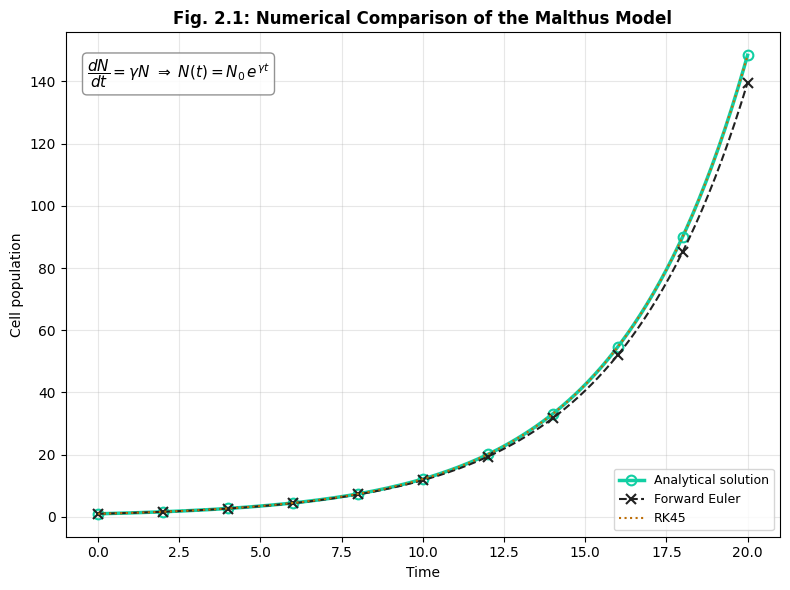

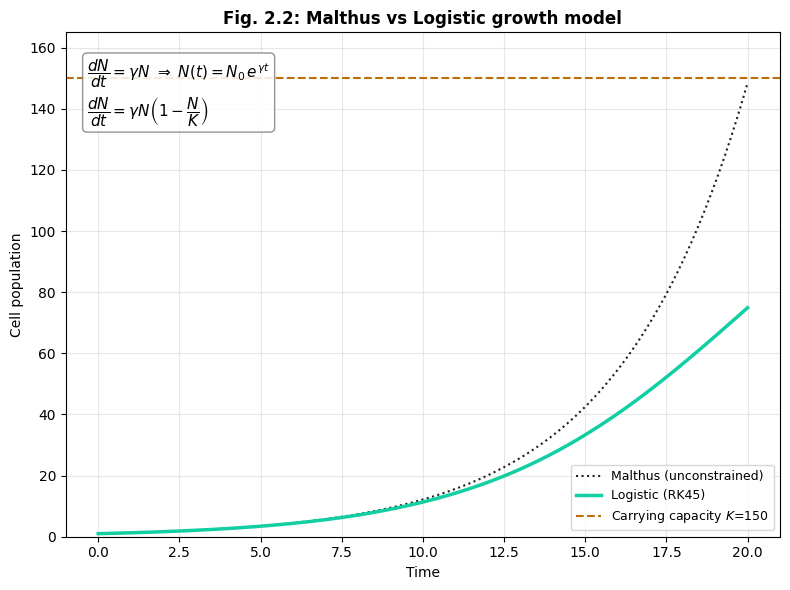

In [4]:
#Fig. 1: Malthus growth model
fig0, ax = plt.subplots(figsize=(8, 6))
ax.set_title('Fig. 2.1: Numerical Comparison of the Malthus Model', fontsize=12, fontweight='bold')
ax.plot(t_euler, N_exact, color=colN1, lw=2.5, marker='o', markevery=20, ms=7, mfc='none', mew=1.5, label='Analytical solution')
ax.plot(t_euler, N_euler, color=colTot, lw=1.5, ls='--', marker='x', markevery=20, ms=7, mew=1.5, label='Forward Euler')
ax.plot(sol_malthus.t, sol_malthus.y[0], color=colN2, lw=1.5, ls=':', label='RK45')
ax.text(0.03, 0.95,r'$\dfrac{dN}{dt} = \gamma N \ \Rightarrow\ N(t) = N_0\,e^{\gamma t}$', transform=ax.transAxes, 
        fontsize=11, va='top', bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_xlabel('Time')
ax.set_ylabel('Cell population')
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Fig. 2: Malthus vs Logistic growth model
fig1, ax = plt.subplots(figsize=(8, 6))
ax.set_title('Fig. 2.2: Malthus vs Logistic growth model', fontsize=12, fontweight='bold')
ax.plot(t_euler, N_exact, color=colTot, lw=1.5, ls=':', label='Malthus (unconstrained)')
ax.plot(sol_logistic_single.t, sol_logistic_single.y[0], color=colN1, lw=2.5, label='Logistic (RK45)')
ax.axhline(K_logistic, color=colN2, ls='--', lw=1.5, label=f'Carrying capacity $K$={K_logistic}')
ax.text(0.03, 0.95, r'$\dfrac{dN}{dt} = \gamma N \ \Rightarrow\ N(t) = N_0\,e^{\gamma t}$' + '\n' + 
        r'$\dfrac{dN}{dt} = \gamma N\left(1-\dfrac{N}{K}\right)$', transform=ax.transAxes, fontsize=11, va='top', 
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_xlabel('Time')
ax.set_ylabel('Cell population')
ax.set_ylim(0, max(N_exact.max(), K_logistic) * 1.1)
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Linear HER2 Two-Phenotype Model
The model is extended to describe two interacting populations of HER2+ and HER2− breast cancer cells.

Each population has a distinct proliferation rate, while phenotypic switching allows transitions between the two cell states.

The system is represented by a linear system of ordinary differential equations.

### Analytical Analysis
Eigenvalues and eigenvectors are used to investigate the long-term behavior of the system.

The dominant eigenvalue determines the asymptotic growth rate, while its corresponding eigenvector determines the long-term relative composition of the two populations.

### Numerical Simulations
The model is simulated using numerical integration to investigate:
- The evolution of both cell populations over time.
- Changes in the relative proportions of HER2+ and HER2− cells.
- Convergence toward the asymptotic population composition.
- The influence of different initial conditions.

The analytical results are compared with numerical simulations to examine the consistency of the predicted long-term behavior.


In [5]:
print("\nChapter 3. Linear HER2 two-phenotype model")

# Two-phenotype model, no density limitation
def baseline_model(t, y):
    N1, N2 = y
    dN1_dt = K1 * N1 + K21 * N2
    dN2_dt = K2 * N2 + K12 * N1
    return [dN1_dt, dN2_dt]

# check hand analysis
print("\nCheck of the hand-derived analysis")
# discriminant of the characteristic equation
disc = (K1 - K2)**2 + 4 * K12 * K21

# eigenvalues
lambda_plus = 0.5 * ((K1 + K2) + np.sqrt(disc))
lambda_minus = 0.5 * ((K1 + K2) - np.sqrt(disc))

#frpm the dominant eigenvector, normalized -> asymptotic fractions of HER2+ and HER2- cells, independently of the initial population composition
p1_hand = (lambda_plus - K2) / ((lambda_plus - K2) + K12)
p2_hand = 1 - p1_hand

print(f"lambda+ = {lambda_plus:.3f}, lambda- = {lambda_minus:.3f}")
print(f"p1 (HER2+) = {p1_hand:.3f}, p2 (HER2-) = {p2_hand:.3f}")

# check with numpy
R = np.array([[K1, K21], [K12, K2]])
print(np.linalg.eigvals(R))

# Numerical simulation
t_span_linear = (0,30)
t_eval_linear = np.linspace(0,30,500) #evaluation points

# mixed initial population: HER2+ and HER2-
y0_linear = [1, 1]
sol_lin = solve_ivp(baseline_model, t_span_linear, y0_linear, t_eval=t_eval_linear, method='RK45')

#phenotype fractions over time
frac_HER2_pos_linear = sol_lin.y[0] / sol_lin.y.sum(axis=0)
frac_HER2_neg_linear = 1 - frac_HER2_pos_linear

print("\nNumerical simulation")
print("Final phenotype fractions (mixed initial population):")
print(f"HER2+ = {frac_HER2_pos_linear[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_linear[-1]:.3f}")
print("Analytical asymptotic fractions:")
print(f"HER2+ = {p1_hand:.3f}")
print(f"HER2- = {p2_hand:.3f}")

#Validation with different initial conditions
y0_only_HER2_pos = [1, 0] #only HER2+ at t=0
y0_only_HER2_neg = [0, 1] #only HER2- at t=0

sol_lin_pos = solve_ivp(baseline_model, t_span_linear, y0_only_HER2_pos, t_eval=t_eval_linear, method='RK45')
sol_lin_neg = solve_ivp(baseline_model, t_span_linear, y0_only_HER2_neg, t_eval=t_eval_linear, method='RK45')

#HER2+ fraction for the two additional initial conditions
frac_lin_pos = sol_lin_pos.y[0] / sol_lin_pos.y.sum(axis=0)
frac_lin_neg = sol_lin_neg.y[0] / sol_lin_neg.y.sum(axis=0) #HER2+ fraction della simulazione che parte da HER2- only

print("\nValidation using different initial conditions")
print(f"Initial condition [1,0] -> HER2+ fraction = {frac_lin_pos[-1]:.3f}")
print(f"Initial condition [0,1] -> HER2+ fraction = {frac_lin_neg[-1]:.3f}")
print(f"Analytical prediction   -> HER2+ fraction = {p1_hand:.3f}")


Chapter 3. Linear HER2 two-phenotype model

Check of the hand-derived analysis
lambda+ = 1.025, lambda- = 0.675
p1 (HER2+) = 0.783, p2 (HER2-) = 0.217
[1.02492856 0.67507144]

Numerical simulation
Final phenotype fractions (mixed initial population):
HER2+ = 0.783
HER2- = 0.217
Analytical asymptotic fractions:
HER2+ = 0.783
HER2- = 0.217

Validation using different initial conditions
Initial condition [1,0] -> HER2+ fraction = 0.783
Initial condition [0,1] -> HER2+ fraction = 0.783
Analytical prediction   -> HER2+ fraction = 0.783


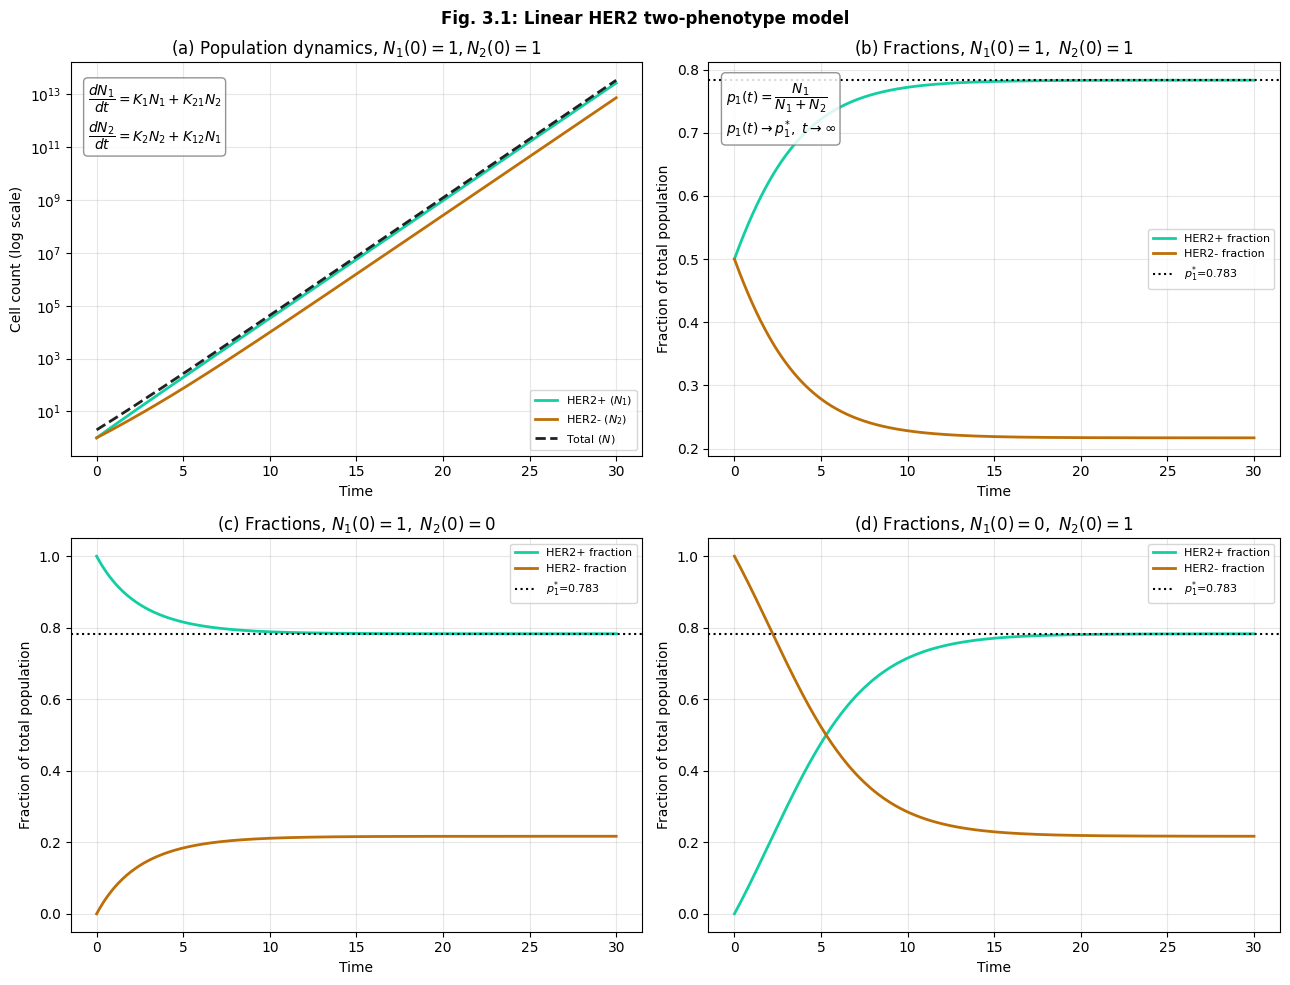

In [6]:
# Fig. 3: Linear HER2 two-phenotype model
fig3, axes3 = plt.subplots(2, 2, figsize=(13, 10))
fig3.suptitle('Fig. 3.1: Linear HER2 two-phenotype model', fontsize=12, fontweight='bold')
ax = axes3[0, 0]
ax.semilogy(sol_lin.t, sol_lin.y[0], color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.semilogy(sol_lin.t, sol_lin.y[1], color=colN2, lw=2, label='HER2- ($N_2$)')
ax.semilogy(sol_lin.t, sol_lin.y.sum(axis=0), color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.text(0.03, 0.95, r'$\dfrac{dN_1}{dt}=K_1N_1+K_{21}N_2$' + '\n' + r'$\dfrac{dN_2}{dt}=K_2N_2+K_{12}N_1$',
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_title('(a) Population dynamics, $N_1(0)=1, N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count (log scale)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

ax = axes3[0, 1]
ax.plot(sol_lin.t, frac_HER2_pos_linear, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_lin.t, frac_HER2_neg_linear, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.text(0.03, 0.95, r'$p_1(t)=\dfrac{N_1}{N_1+N_2}$' + '\n' + r'$p_1(t)\rightarrow p_1^{*},\ t\rightarrow\infty$',
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_title('(b) Fractions, $N_1(0)=1,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes3[1, 0]
ax.plot(sol_lin_pos.t, frac_lin_pos, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_lin_pos.t, 1 - frac_lin_pos, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.set_title('(c) Fractions, $N_1(0)=1,\\ N_2(0)=0$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes3[1, 1]
ax.plot(sol_lin_neg.t, frac_lin_neg, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_lin_neg.t, 1 - frac_lin_neg, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.set_title('(d) Fractions, $N_1(0)=0,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Shared Logistic HER2 Model

The linear two-phenotype model is extended by introducing density-dependent growth.

Both HER2+ and HER2− populations share a common carrying capacity, which limits total tumor growth.

### Model Assumptions

The proliferation and phenotype-transition terms are multiplied by a shared crowding factor that depends on the total cell population.

As the tumor approaches its carrying capacity, the net population growth rate decreases.

### Numerical Analysis

The simulations investigate:

- HER2+ and HER2− population growth under density limitations.
- The evolution of the total tumor population.
- Convergence toward the carrying capacity.
- Changes in the relative abundance of the two phenotypes.

This model provides an intermediate step between unrestricted linear growth and models incorporating explicit interpopulation competition.


In [7]:
print("\nChapter 4. Shared Logistic HER2 Model")

#Shared logistic regulation - common crowding factor 1-N/C, same for both phenotypes
def logistic_model(t, y):
    N1, N2 = y
    crowding_factor = 1 - (N1 + N2) / C
    dN1_dt = (K1 * N1 + K21 * N2) * crowding_factor
    dN2_dt = (K2 * N2 + K12 * N1) * crowding_factor
    return [dN1_dt, dN2_dt]

# Numerical simulation
t_span_logistic = (0, 30)
t_eval_logistic = np.linspace(0, 30, 500)

#mixed initial population
y0_logistic = [1,1]
sol_logistic = solve_ivp(logistic_model, t_span_logistic, y0_logistic, t_eval=t_eval_logistic, method='RK45')

N_total_logistic = sol_logistic.y.sum(axis=0)
frac_HER2_pos_logistic = sol_logistic.y[0] / N_total_logistic
frac_HER2_neg_logistic = 1-frac_HER2_pos_logistic

#Validation with different initial conditions
y0_only_HER2_pos_log = [1, 0] #only HER2+ at t=0
y0_only_HER2_neg_log = [0, 1] #only HER2- at t=0
sol_logistic_pos = solve_ivp(logistic_model, t_span_logistic, [1,0], t_eval=t_eval_logistic, method="RK45")
sol_logistic_neg = solve_ivp(logistic_model, t_span_logistic, [0,1], t_eval=t_eval_logistic, method="RK45")
frac_logistic_pos = sol_logistic_pos.y[0] / sol_logistic_pos.y.sum(axis=0)
frac_logistic_neg = sol_logistic_neg.y[0] / sol_logistic_neg.y.sum(axis=0)

print("\nNumerical simulation")
print("Final logistic population")
print(f"Total cells = {N_total_logistic[-1]:.0f}")
print(f"Carrying capacity C = {C:.0f}")
print("Final phenotype fractions")
print(f"HER2+ = {frac_HER2_pos_logistic[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_logistic[-1]:.3f}")


Chapter 4. Shared Logistic HER2 Model

Numerical simulation
Final logistic population
Total cells = 999258
Carrying capacity C = 1000000
Final phenotype fractions
HER2+ = 0.779
HER2- = 0.221


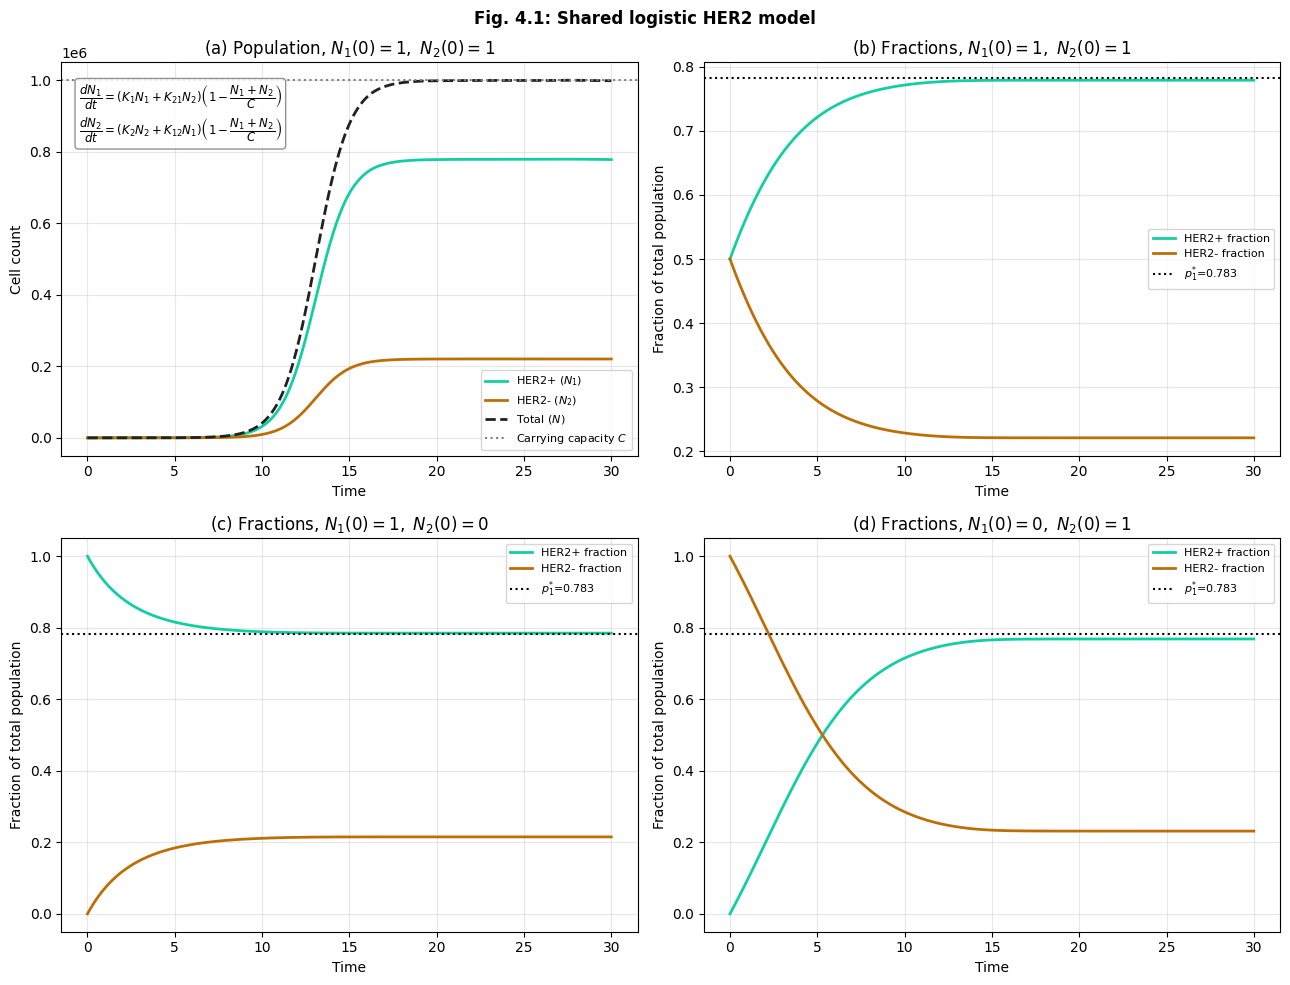

In [8]:
# --- Chapter 4. Shared logistic HER2 model ---
#Fig. 4: Shared logistic HER2 model
fig4, axes4 = plt.subplots(2, 2, figsize=(13, 10))
fig4.suptitle('Fig. 4.1: Shared logistic HER2 model', fontsize=12, fontweight='bold')
ax = axes4[0, 0]
ax.plot(sol_logistic.t, sol_logistic.y[0], color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.plot(sol_logistic.t, sol_logistic.y[1], color=colN2, lw=2, label='HER2- ($N_2$)')
ax.plot(sol_logistic.t, N_total_logistic, color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.axhline(C, color='gray', ls=':', label='Carrying capacity $C$')
ax.text(0.03, 0.95, r'$\dfrac{dN_1}{dt}=(K_1N_1+K_{21}N_2)\left(1-\dfrac{N_1+N_2}{C}\right)$' + '\n' 
        + r'$\dfrac{dN_2}{dt}=(K_2N_2+K_{12}N_1)\left(1-\dfrac{N_1+N_2}{C}\right)$',
        transform=ax.transAxes, fontsize=8.5, va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_title('(a) Population, $N_1(0)=1,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes4[0, 1]
ax.plot(sol_logistic.t, frac_HER2_pos_logistic, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_logistic.t, frac_HER2_neg_logistic, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.set_title('(b) Fractions, $N_1(0)=1,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes4[1, 0]
ax.plot(sol_logistic_pos.t, frac_logistic_pos, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_logistic_pos.t, 1 - frac_logistic_pos, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.set_title('(c) Fractions, $N_1(0)=1,\\ N_2(0)=0$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes4[1, 1]
ax.plot(sol_logistic_neg.t, frac_logistic_neg, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_logistic_neg.t, 1 - frac_logistic_neg, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(p1_hand, color='black', ls=':', label=f'$p_1^{{*}}$={p1_hand:.3f}')
ax.set_title('(d) Fractions, $N_1(0)=0,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Competition and Phenotypic Plasticity

The shared logistic model is extended to include asymmetric competition between HER2+ and HER2− cell populations.

The **4C competition model** introduces separate crowding factors for the two phenotypes.

The competition coefficients determine how strongly each population affects the growth of the other.

### Analytical Equilibrium

The coexistence equilibrium is obtained by examining the conditions under which both population growth rates vanish.

The analytical equilibrium is used to estimate the expected long-term population sizes and phenotype proportions.

### Numerical Simulations

Numerical integration is used to investigate:

- Population dynamics under asymmetric competition.
- The evolution of HER2+ and HER2− proportions.
- Convergence toward the coexistence equilibrium.
- Agreement between analytical and numerical equilibrium estimates.

The model illustrates how density limitations, competition, and phenotypic switching jointly influence tumor composition.


In [9]:
print("\nChapter 5. 4C Competition Model")

def model_4c(t, y):
    N1, N2 = y
    crowding_1 = 1 - (N1 + C12 * N2) / C
    crowding_2 = 1 - (N2 + C21 * N1) / C
    dN1_dt = (K1 * N1 + K21 * N2) * crowding_1
    dN2_dt = (K2 * N2 + K12 * N1) * crowding_2
    return [dN1_dt, dN2_dt]

# Analytic coexistence equilibrium E*: both crowding factors = 0
denom = 1- C12 * C21
N1_star = C * (1-C12) / denom
N2_star = C * (1-C21) / denom
p1_star = N1_star / (N1_star + N2_star)
stable_4c = (0 < C12 < 1) and (0 < C21 < 1)

print("\nAnalytic Equilibrium - 4C Competition Model")
print(f"E* = (N1*, N2*) = ({N1_star:.1f}, {N2_star:.1f})")
print(f"p1* (HER2+ fraction at E*) = {p1_star:.4f}  (vs. linear-model {p1_hand:.4f})")
print(f"Stability (0 < C12, C21 < 1)    = {stable_4c}")

# Numerical simulation
t_span_4c = (0,30)
t_eval_4c = np.linspace(0,30,500)
#mixed initial population
y0_4c = [1,1]
sol_4c = solve_ivp(model_4c, t_span_4c, y0_4c, t_eval=t_eval_4c, method='RK45')

N_total_4c = sol_4c.y.sum(axis=0)
frac_HER2_pos_4c = sol_4c.y[0] / N_total_4c
frac_HER2_neg_4c = 1-frac_HER2_pos_4c

print("\nNumerical simulation")
print(f"Final HER2+ population = {sol_4c.y[0, -1]:.0f}")
print(f"Final HER2- population = {sol_4c.y[1, -1]:.0f}")
print("\nAnalytical equilibrium")
print(f"N1* = {N1_star:.0f}")
print(f"N2* = {N2_star:.0f}")
print("\nFinal phenotype fractions")
print(f"HER2+ = {frac_HER2_pos_4c[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_4c[-1]:.3f}")
print(f"Analytical HER2+ equilibrium fraction = {p1_star:.3f}")


Chapter 5. 4C Competition Model

Analytic Equilibrium - 4C Competition Model
E* = (N1*, N2*) = (882352.9, 294117.6)
p1* (HER2+ fraction at E*) = 0.7500  (vs. linear-model 0.7831)
Stability (0 < C12, C21 < 1)    = True

Numerical simulation
Final HER2+ population = 883160
Final HER2- population = 291436

Analytical equilibrium
N1* = 882353
N2* = 294118

Final phenotype fractions
HER2+ = 0.752
HER2- = 0.248
Analytical HER2+ equilibrium fraction = 0.750


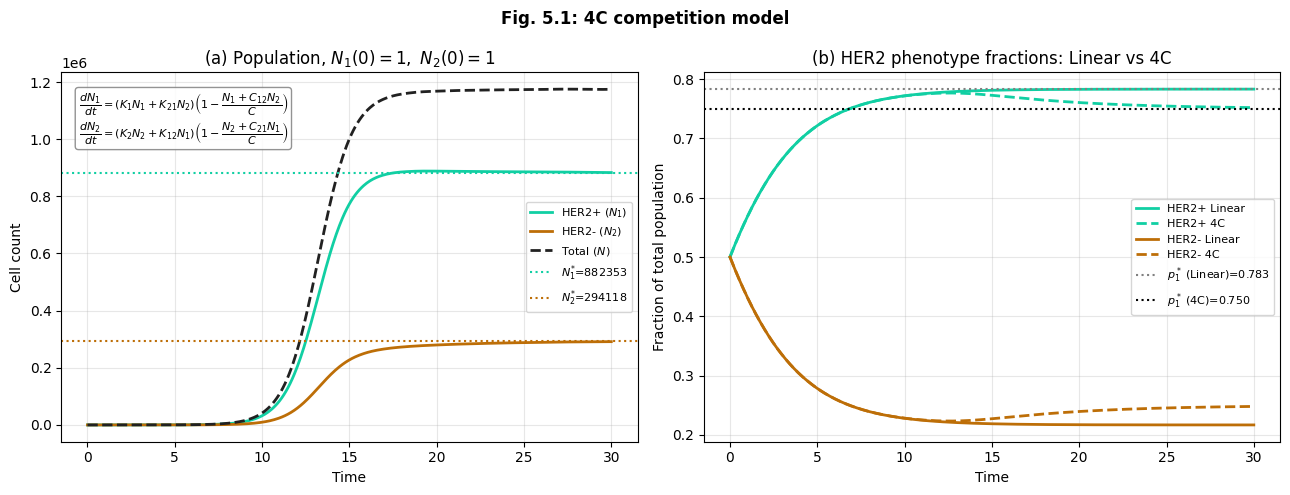

In [10]:
# --- Chapter 5. 4C Competition Model ---
# Fig. 5. 4C competition model
fig5, axes5 = plt.subplots(1, 2, figsize=(13, 5))
fig5.suptitle('Fig. 5.1: 4C competition model', fontsize=12, fontweight='bold')
ax = axes5[0]
ax.plot(sol_4c.t, sol_4c.y[0], color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.plot(sol_4c.t, sol_4c.y[1], color=colN2, lw=2, label='HER2- ($N_2$)')
ax.plot(sol_4c.t, N_total_4c, color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.axhline(N1_star, color=colN1, ls=':', lw=1.5, label=f'$N_1^{{*}}$={N1_star:.0f}')
ax.axhline(N2_star, color=colN2, ls=':', lw=1.5, label=f'$N_2^{{*}}$={N2_star:.0f}')
ax.text(0.03, 0.95, r'$\dfrac{dN_1}{dt}=(K_1N_1+K_{21}N_2)\left(1-\dfrac{N_1+C_{12}N_2}{C}\right)$' + '\n' 
        + r'$\dfrac{dN_2}{dt}=(K_2N_2+K_{12}N_1)\left(1-\dfrac{N_2+C_{21}N_1}{C}\right)$',
        transform=ax.transAxes, fontsize=8, va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax.set_title('(a) Population, $N_1(0)=1,\\ N_2(0)=1$')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes5[1]
ax.plot(sol_lin.t, frac_HER2_pos_linear, color=colN1, lw=2, label='HER2+ Linear')
ax.plot(sol_4c.t, frac_HER2_pos_4c, color=colN1, lw=2, ls='--', label='HER2+ 4C')
ax.plot(sol_lin.t, frac_HER2_neg_linear, color=colN2, lw=2, label='HER2- Linear')
ax.plot(sol_4c.t, frac_HER2_neg_4c, color=colN2, lw=2, ls='--', label='HER2- 4C')
ax.axhline(p1_hand, color='gray', ls=':', lw=1.5, label=fr'$p_1^*$ (Linear)={p1_hand:.3f}')
ax.axhline(p1_star, color='black', ls=':', lw=1.5, label=fr'$p_1^*$ (4C)={p1_star:.3f}')
ax.set_title('(b) HER2 phenotype fractions: Linear vs 4C')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Mathematical Modeling of Treatment Effects

The competition model is extended to investigate the effects of therapeutic interventions on tumor population dynamics.

Three treatment scenarios are considered.

### 6.1 Paclitaxel Monotherapy

Paclitaxel is represented by an additional treatment-induced death term acting on the HER2+ population.

Drug activity varies over time according to a prescribed dosing schedule and a relaxation-time parameter.

### 6.2 Notch Inhibition

Notch inhibition is modeled through a treatment-dependent reduction in the proliferation of HER2− cells.

The model includes a dynamic representation of inhibitor activity and its influence on population growth.

### 6.3 Combined Therapy

The combined treatment model incorporates both Paclitaxel-induced cell death and Notch-mediated proliferation inhibition.

### Numerical Simulations

The simulations compare:

- Tumor population dynamics under each intervention.
- Changes in HER2+ and HER2− composition.
- Total tumor population during and after treatment.
- The effects of applying both therapeutic mechanisms simultaneously.

These models represent simplified theoretical treatment mechanisms rather than clinically validated drug-response predictions.


In [11]:
print("\nChapter 6. Therapy models")

### Chapter 6.1 - Paclitaxel: additional death term on HER2+, proportional to drug activity
tau_P = 0.5 #relaxation time constant of drug activity
d_max = 0.8 #maximum drug-induced death rate

#dosing schedule
dose_start = 3
dose_end = 5
dose_level = 1

def P_f(t):
    if dose_start <= t < dose_end:
        return dose_level
    return 0

def chemotherapy_model(t, y):
    N1, N2, P = y
    crowding_1 = 1-(N1 + C12*N2)/C
    crowding_2 = 1-(N2 + C21*N1)/C
    dN1_dt = (K1*N1 + K21*N2)*crowding_1 - d_max*P*N1
    dN2_dt = (K2*N2 + K12*N1)*crowding_2             
    dP_dt = (P_f(t) - P)/tau_P
    return [dN1_dt, dN2_dt, dP_dt]

# Numerical simulation - Paclitaxel
t_span_chemo = (0, 10)
t_eval_chemo = np.linspace(0, 10, 501)

#initial tumor population, starting from the linear-model equilibrium composition
N_total_0 = 5000
N1_0 = 0.78 * N_total_0
N2_0 = 0.22 * N_total_0

#initial drug activity
P0 = 0
y0_chemo = [N1_0, N2_0, P0]

# max_step keeps the adaptive solver from stepping over the dose on/off jumps at t=3, t=5
sol_chemo = solve_ivp(chemotherapy_model, t_span_chemo, y0_chemo, t_eval=t_eval_chemo, method="RK45", max_step=0.05)

#Extract solutions
N1_chemo = sol_chemo.y[0]
N2_chemo = sol_chemo.y[1]
P_chemo = sol_chemo.y[2]
# Total tumor population
N_total_chemo = N1_chemo + N2_chemo
# Phenotype fractions
frac_HER2_pos_chemo = N1_chemo / N_total_chemo
frac_HER2_neg_chemo = N2_chemo / N_total_chemo

print("\nPaclitaxel monotherapy")
print(f"Initial total population = {N_total_0:.0f}")
print(f"Final total population = {N_total_chemo[-1]:.0f}")
print("\nFinal phenotype fractions")
print(f"HER2+ = {frac_HER2_pos_chemo[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_chemo[-1]:.3f}")

### Chapter 6.2 - Notch inhibitor
#working values
beta_A = 1e-6     #receptor-binding rate
H = 1.0           #receptor abundance scale
eta_A = 1.0       #inhibition strength

dose_start_notch = 3
dose_end_notch = 5
dose_level_notch = 1

t_A_star = dose_start_notch #time after which inhibition becomes active

#free administered Notch inhibitor
def A_f(t):
    if dose_start_notch <= t < dose_end_notch:
        return dose_level_notch
    return 0

#effective Notch inhibition
def f_notch(Ab, t):
    if t > t_A_star:
        return eta_A * Ab
    return 0

#Notch inhibitor
def notch_model(t, y):
    N1, N2, Ab = y
    crowding_1 = 1 - (N1 + C12 * N2) / C
    crowding_2 = 1 - (N2 + C21 * N1) / C
    dN1_dt = ((K1 * N1 + K21 * N2) * crowding_1)
    inhibition = f_notch(Ab, t)
    dN2_dt = ((K2 * N2 * (1 - inhibition) + K12 * N1)* crowding_2)
    if A_f(t) > 0:
        dAb_dt = (beta_A* (A_f(t) - Ab)*(H * N2 - Ab))
    else:
        dAb_dt = 0
    return [dN1_dt, dN2_dt, dAb_dt]

# Numerical simulation - Notch
t_span_notch = (0,10)
t_eval_notch = np.linspace(0,10,501)

#initial amount of bound inhibitor
Ab0 = 0
y0_notch = [N1_0, N2_0, Ab0]
sol_notch = solve_ivp(notch_model, t_span_notch, y0_notch, t_eval=t_eval_notch, method="RK45", max_step=0.05)

#extract solutions
N1_notch = sol_notch.y[0]
N2_notch = sol_notch.y[1]
Ab_notch = sol_notch.y[2]

N_total_notch = N1_notch + N2_notch
frac_HER2_pos_notch = N1_notch / N_total_notch
frac_HER2_neg_notch = N2_notch / N_total_notch

print("\nNotch inhibitor monotherapy")
print(f"Initial total population = {N_total_0:.0f}")
print(f"Final total population   = {N_total_notch[-1]:.0f}")
print("\nFinal phenotype fractions")
print(f"HER2+ = {frac_HER2_pos_notch[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_notch[-1]:.3f}")

### Chapter 6.3 - Combined therapy: Paclitaxel death term on HER2+, Notch inhibition on HER2- proliferation
def combined_therapy_model(t, y):
    N1, N2, P, Ab = y
    crowding_1 = 1 - (N1 + C12 * N2) / C
    crowding_2 = 1 - (N2 + C21 * N1) / C
    inhibition = f_notch(Ab, t)
    dN1_dt = ((K1 * N1 + K21 * N2) * crowding_1 - d_max * P * N1)
    dN2_dt = ((K2 * N2 * (1 - inhibition) + K12 * N1) * crowding_2)
    dP_dt = (P_f(t) - P) / tau_P #paclitaxel pharmacodynamics
    if A_f(t) > 0: #Notch inhibitor receptor-binding dynamics
        dAb_dt = (beta_A* (A_f(t) - Ab)* (H * N2 - Ab))
    else:
        dAb_dt = 0
    return [dN1_dt, dN2_dt, dP_dt, dAb_dt]

# Numerical simulation - combined therapy
t_span_combined = (0, 10)
t_eval_combined = np.linspace(0, 10, 501)

#initial conditions
P0 = 0
Ab0 = 0
y0_combined = [N1_0, N2_0, P0, Ab0]
sol_combined = solve_ivp(combined_therapy_model, t_span_combined, y0_combined, t_eval=t_eval_combined, method="RK45", max_step=0.05)

#extract solutions
N1_combined = sol_combined.y[0]
N2_combined = sol_combined.y[1]
P_combined = sol_combined.y[2]
Ab_combined = sol_combined.y[3]

N_total_combined = N1_combined + N2_combined

frac_HER2_pos_combined = N1_combined / N_total_combined
frac_HER2_neg_combined = N2_combined / N_total_combined

print("\nCombined therapy")
print(f"Initial total population = {N_total_0:.0f}")
print(f"Final total population   = {N_total_combined[-1]:.0f}")
print("\nFinal phenotype fractions")
print(f"HER2+ = {frac_HER2_pos_combined[-1]:.3f}")
print(f"HER2- = {frac_HER2_neg_combined[-1]:.3f}")

#post therapy values (trova la posizione corrispondente a t=5 (indice))
idx_chemo_5 = np.argmin(np.abs(sol_chemo.t - 5))
idx_notch_5 = np.argmin(np.abs(sol_notch.t - 5))
idx_combined_5 = np.argmin(np.abs(sol_combined.t - 5))
print("\nTotal population at the end of scheduled drug administration (t = 5)")
print(f"Paclitaxel = {N_total_chemo[idx_chemo_5]:.0f}")
print(f"Notch      = {N_total_notch[idx_notch_5]:.0f}")
print(f"Combined   = {N_total_combined[idx_combined_5]:.0f}")


Chapter 6. Therapy models

Paclitaxel monotherapy
Initial total population = 5000
Final total population = 1177076

Final phenotype fractions
HER2+ = 0.671
HER2- = 0.329

Notch inhibitor monotherapy
Initial total population = 5000
Final total population   = 1149155

Final phenotype fractions
HER2+ = 0.775
HER2- = 0.225

Combined therapy
Initial total population = 5000
Final total population   = 1163944

Final phenotype fractions
HER2+ = 0.688
HER2- = 0.312

Total population at the end of scheduled drug administration (t = 5)
Paclitaxel = 243279
Notch      = 484083
Combined   = 239056


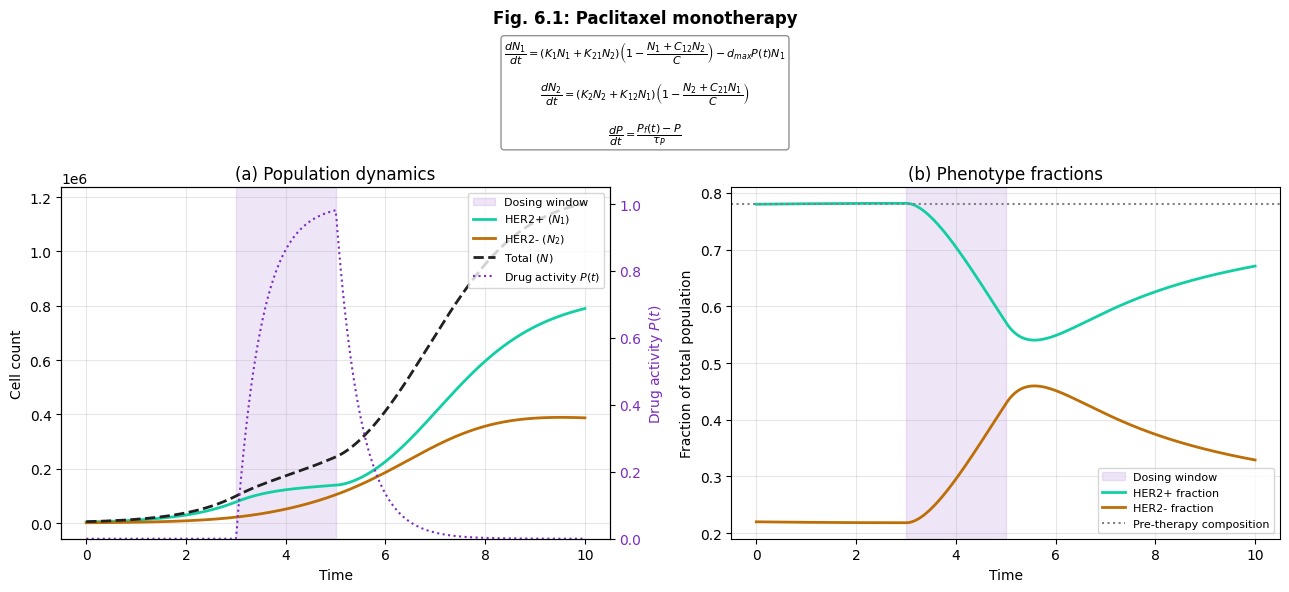

In [12]:
#Fig. 6: Paclitaxel monotherapy
colDrug = '#7B2CBF'

fig6, axes6 = plt.subplots(1, 2, figsize=(13, 6))
fig6.suptitle('Fig. 6.1: Paclitaxel monotherapy', fontsize=12, fontweight='bold', y=0.98)
fig6.text(0.5, 0.93, r'$\dfrac{dN_1}{dt}=(K_1N_1+K_{21}N_2)\left(1-\dfrac{N_1+C_{12}N_2}{C}\right) -d_{max}P(t)N_1$' + '\n' + '\n'
          + r'$\dfrac{dN_2}{dt}=(K_2N_2+K_{12}N_1)\left(1-\dfrac{N_2+C_{21}N_1}{C}\right)$' + '\n' + '\n'
          + r'$\dfrac{dP}{dt}=\dfrac{P_f(t)-P}{\tau_P}$',
          ha='center', va='top', fontsize=8,
          bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax = axes6[0]
ax.axvspan(dose_start, dose_end, color=colDrug, alpha=0.12, label='Dosing window')
ax.plot(sol_chemo.t, N1_chemo, color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.plot(sol_chemo.t, N2_chemo, color=colN2, lw=2, label='HER2- ($N_2$)')
ax.plot(sol_chemo.t, N_total_chemo, color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.set_title('(a) Population dynamics')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.plot(sol_chemo.t, P_chemo, color=colDrug, lw=1.5, ls=':', label='Drug activity $P(t)$')
ax2.set_ylabel('Drug activity $P(t)$', color=colDrug)
ax2.tick_params(axis='y', labelcolor=colDrug)
ax2.set_ylim(0, 1.05)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper right')

ax = axes6[1]
ax.axvspan(dose_start, dose_end, color=colDrug, alpha=0.12, label='Dosing window')
ax.plot(sol_chemo.t, frac_HER2_pos_chemo, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_chemo.t, frac_HER2_neg_chemo, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(0.78, color='gray', ls=':', lw=1.5, label='Pre-therapy composition')
ax.set_title('(b) Phenotype fractions')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.80])
plt.show()


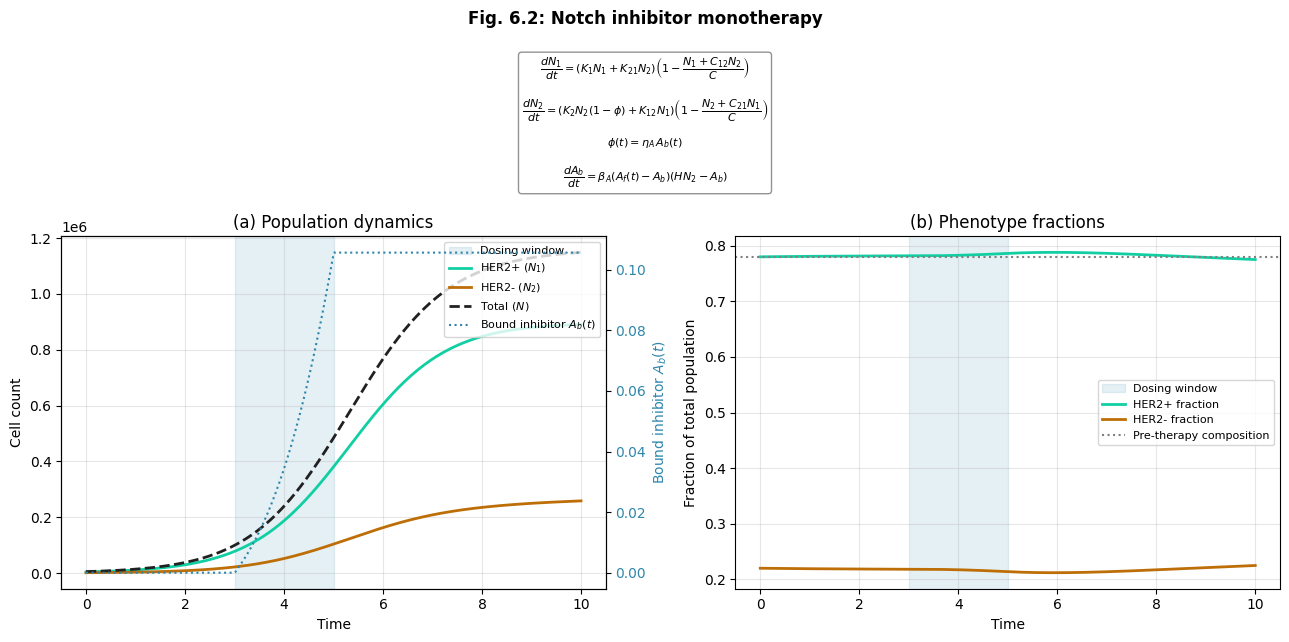

In [13]:
#Fig. 7: Notch inhibitor monotherapy
colNotch = '#2E86AB'

fig7, axes7 = plt.subplots(1, 2, figsize=(13, 6.5))
fig7.suptitle('Fig. 6.2: Notch inhibitor monotherapy', fontsize=12, fontweight='bold', y=0.98)
fig7.text(0.5, 0.91, r'$\dfrac{dN_1}{dt}=(K_1N_1+K_{21}N_2)\left(1-\dfrac{N_1+C_{12}N_2}{C}\right)$' + '\n' + '\n'
          + r'$\dfrac{dN_2}{dt}=\left(K_2N_2(1-\phi)+K_{12}N_1\right)\left(1-\dfrac{N_2+C_{21}N_1}{C}\right)$' + '\n' + '\n'
          + r'$\phi(t)=\eta_A\,A_b(t)$' + '\n' + '\n'
          + r'$\dfrac{dA_b}{dt}=\beta_A\left(A_f(t)-A_b\right)\left(H N_2-A_b\right)$',
          ha='center', va='top', fontsize=8,
          bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax = axes7[0]
ax.axvspan(dose_start_notch, dose_end_notch, color=colNotch, alpha=0.12, label='Dosing window')
ax.plot(sol_notch.t, N1_notch, color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.plot(sol_notch.t, N2_notch, color=colN2, lw=2, label='HER2- ($N_2$)')
ax.plot(sol_notch.t, N_total_notch, color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.set_title('(a) Population dynamics')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.plot(sol_notch.t, Ab_notch, color=colNotch, lw=1.5, ls=':', label='Bound inhibitor $A_b(t)$')
ax2.set_ylabel('Bound inhibitor $A_b(t)$', color=colNotch)
ax2.tick_params(axis='y', labelcolor=colNotch)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper right')

ax = axes7[1]
ax.axvspan(dose_start_notch, dose_end_notch, color=colNotch, alpha=0.12, label='Dosing window')
ax.plot(sol_notch.t, frac_HER2_pos_notch, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_notch.t, frac_HER2_neg_notch, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(0.78, color='gray', ls=':', lw=1.5, label='Pre-therapy composition')
ax.set_title('(b) Phenotype fractions')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.74])
plt.show()

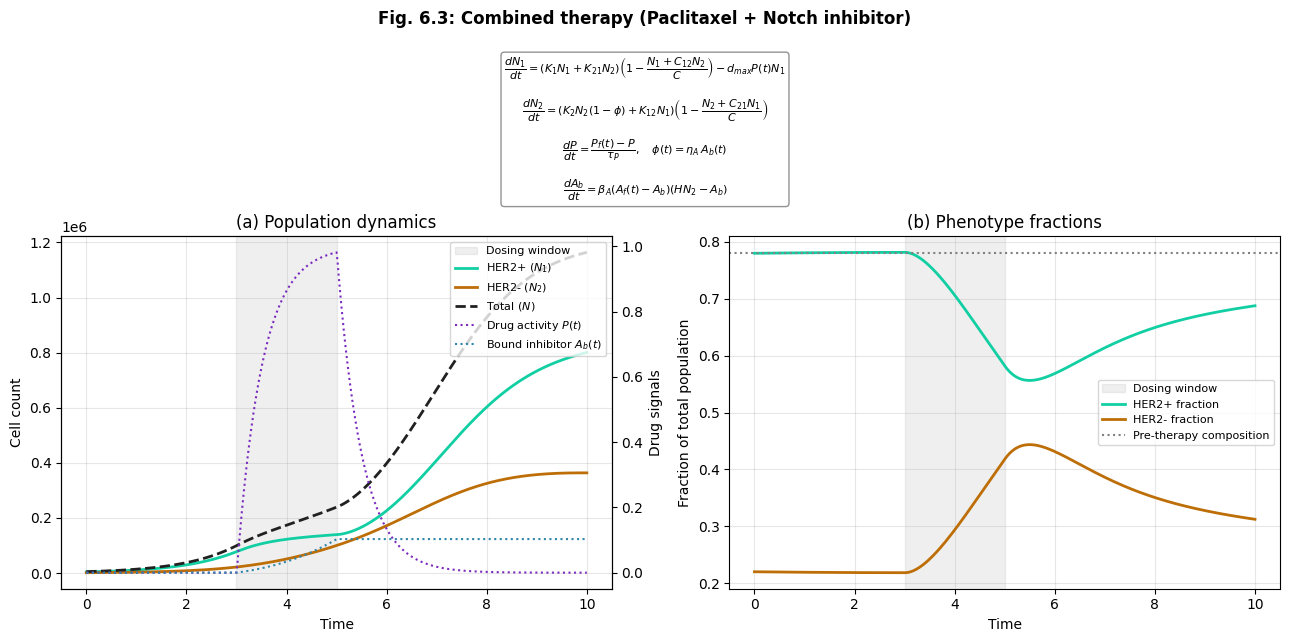

In [14]:
#Fig. 8: Combined therapy (Paclitaxel + Notch inhibitor)
fig8, axes8 = plt.subplots(1, 2, figsize=(13, 6.5))
fig8.suptitle('Fig. 6.3: Combined therapy (Paclitaxel + Notch inhibitor)', fontsize=12, fontweight='bold', y=0.98)
fig8.text(0.5, 0.91, r'$\dfrac{dN_1}{dt}=(K_1N_1+K_{21}N_2)\left(1-\dfrac{N_1+C_{12}N_2}{C}\right) -d_{max}P(t)N_1$' + '\n' + '\n'
          + r'$\dfrac{dN_2}{dt}=\left(K_2N_2(1-\phi)+K_{12}N_1\right)\left(1-\dfrac{N_2+C_{21}N_1}{C}\right)$' + '\n' + '\n'
          + r'$\dfrac{dP}{dt}=\dfrac{P_f(t)-P}{\tau_P},\quad \phi(t)=\eta_A\,A_b(t)$' + '\n' + '\n'
          + r'$\dfrac{dA_b}{dt}=\beta_A\left(A_f(t)-A_b\right)\left(H N_2-A_b\right)$',
          ha='center', va='top', fontsize=8,
          bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.85))
ax = axes8[0]
ax.axvspan(dose_start, dose_end, color='gray', alpha=0.12, label='Dosing window')
ax.plot(sol_combined.t, N1_combined, color=colN1, lw=2, label='HER2+ ($N_1$)')
ax.plot(sol_combined.t, N2_combined, color=colN2, lw=2, label='HER2- ($N_2$)')
ax.plot(sol_combined.t, N_total_combined, color=colTot, lw=2, ls='--', label='Total ($N$)')
ax.set_title('(a) Population dynamics')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.plot(sol_combined.t, P_combined, color=colDrug, lw=1.5, ls=':', label='Drug activity $P(t)$')
ax2.plot(sol_combined.t, Ab_combined, color=colNotch, lw=1.5, ls=':', label='Bound inhibitor $A_b(t)$')
ax2.set_ylabel('Drug signals')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper right')

ax = axes8[1]
ax.axvspan(dose_start, dose_end, color='gray', alpha=0.12, label='Dosing window')
ax.plot(sol_combined.t, frac_HER2_pos_combined, color=colN1, lw=2, label='HER2+ fraction')
ax.plot(sol_combined.t, frac_HER2_neg_combined, color=colN2, lw=2, label='HER2- fraction')
ax.axhline(0.78, color='gray', ls=':', lw=1.5, label='Pre-therapy composition')
ax.set_title('(b) Phenotype fractions')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.74])
plt.show()

## 7. Treatment Sequencing

This section investigates how the order of therapeutic administration influences tumor population dynamics.

Three treatment strategies are simulated:

1. **Chemotherapy → Targeted therapy:** Paclitaxel is administered first, followed by Notch inhibition.
2. **Targeted therapy → Chemotherapy:** Notch inhibition is administered first, followed by Paclitaxel.
3. **Simultaneous treatment:** Both therapeutic mechanisms are applied during the same treatment interval.

### Numerical Comparison

The simulations evaluate differences in:

- Total tumor population at the end of treatment.
- Long-term tumor population size.
- HER2+ and HER2− population trajectories.
- Final phenotype composition.

The objective is to investigate whether treatment scheduling alters the theoretical response of a heterogeneous tumor population.

Differences between the simulated strategies depend on the selected model parameters, dosing schedules, and assumptions.

In [15]:
print("\nChapter 7. Treatment sequencing")

#treatment inputs:
#1. paclitaxel P(t)
def P_f_seq(t, start, end, dose = 1):
    if start <= t < end:
        return dose
    return 0
#2. notch A_f(t)
def A_f_seq(t, start, end, dose = 1):
    if start <= t < end:
        return dose
    return 0

#sequencing model
def sequencing_model(t, y, chemo_start, chemo_end, notch_start, notch_end):
    N1, N2, P, Ab = y
    crowding_1 = 1-(N1+C12*N2) / C
    crowding_2 = 1-(N2+C21*N1) / C
    Pf = P_f_seq(t, chemo_start, chemo_end)
    Af = A_f_seq(t, notch_start, notch_end)
    if t> notch_start:
        inhibition = eta_A * Ab
    else:
        inhibition = 0
    dN1_dt = (K1*N1+K21*N2) * crowding_1 - d_max * P * N1
    dN2_dt = ((K2 * N2 * (1 - inhibition) + K12 * N1) * crowding_2)
    dP_dt = (Pf - P) / tau_P
    if Af > 0:
        dAb_dt = beta_A * (Af - Ab) * (H * N2 - Ab)
    else:
        dAb_dt = 0
    return [dN1_dt, dN2_dt, dP_dt, dAb_dt]

t_span_seq = (0, 20)
t_eval_seq = np.linspace(0, 20, 1001)
y0_seq = [N1_0, N2_0, 0, 0]

### Chemotherapy (3-5) -> Targeted therapy (5-7)
sol_chemo_targeted = solve_ivp(lambda t, y: sequencing_model(t, y, chemo_start=3, chemo_end=5,
        notch_start=5, notch_end=7), t_span_seq, y0_seq, t_eval=t_eval_seq, method="RK45", max_step=0.05)

N1_chemo_targeted = sol_chemo_targeted.y[0]
N2_chemo_targeted = sol_chemo_targeted.y[1]
P_chemo_targeted = sol_chemo_targeted.y[2]
Ab_chemo_targeted = sol_chemo_targeted.y[3]

N_total_chemo_targeted = N1_chemo_targeted + N2_chemo_targeted
frac_HER2_pos_chemo_targeted = N1_chemo_targeted / N_total_chemo_targeted
frac_HER2_neg_chemo_targeted = N2_chemo_targeted / N_total_chemo_targeted

### Targeted therapy (3-5) -> Chemotherapy (5-7)
sol_targeted_chemo = solve_ivp(lambda t, y: sequencing_model(t, y, chemo_start=5, chemo_end=7,
        notch_start=3, notch_end=5), t_span_seq, y0_seq, t_eval=t_eval_seq, method="RK45", max_step=0.05)

N1_targeted_chemo = sol_targeted_chemo.y[0]
N2_targeted_chemo = sol_targeted_chemo.y[1]
P_targeted_chemo = sol_targeted_chemo.y[2]
Ab_targeted_chemo = sol_targeted_chemo.y[3]

N_total_targeted_chemo = N1_targeted_chemo + N2_targeted_chemo
frac_HER2_pos_targeted_chemo = N1_targeted_chemo / N_total_targeted_chemo
frac_HER2_neg_targeted_chemo = N2_targeted_chemo / N_total_targeted_chemo

### Simultaneous therapy: both drugs [3, 7]
sol_simultaneous = solve_ivp(lambda t, y: sequencing_model(t, y, chemo_start=3, chemo_end=7,
        notch_start=3, notch_end=7), t_span_seq, y0_seq, t_eval=t_eval_seq, method="RK45", max_step=0.05)

N1_simultaneous = sol_simultaneous.y[0]
N2_simultaneous = sol_simultaneous.y[1]
P_simultaneous = sol_simultaneous.y[2]
Ab_simultaneous = sol_simultaneous.y[3]

N_total_simultaneous = N1_simultaneous + N2_simultaneous
frac_HER2_pos_simultaneous = N1_simultaneous / N_total_simultaneous
frac_HER2_neg_simultaneous = N2_simultaneous / N_total_simultaneous

### Comparison of treatment schedules
idx_chemo_7 = np.argmin(np.abs(sol_chemo_targeted.t - 7))
idx_notch_7 = np.argmin(np.abs(sol_targeted_chemo.t - 7))
idx_sim_7 = np.argmin(np.abs(sol_simultaneous.t - 7))
print("\nTumor population at the end of therapy (t = 7)")
print(f"Chemo -> Targeted = {N_total_chemo_targeted[idx_chemo_7]:.0f}")
print(f"Targeted -> Chemo = {N_total_targeted_chemo[idx_notch_7]:.0f}")
print(f"Simultaneous      = {N_total_simultaneous[idx_sim_7]:.0f}")

print("\nFinal tumor population at t = 20")
print(f"Chemo -> Targeted = {N_total_chemo_targeted[-1]:.0f}")
print(f"Targeted -> Chemo = {N_total_targeted_chemo[-1]:.0f}")
print(f"Simultaneous      = {N_total_simultaneous[-1]:.0f}")

print("\nFinal HER2+ fractions at t = 20")
print(f"Chemo -> Targeted = {frac_HER2_pos_chemo_targeted[-1]:.3f}")
print(f"Targeted -> Chemo = {frac_HER2_pos_targeted_chemo[-1]:.3f}")
print(f"Simultaneous      = {frac_HER2_pos_simultaneous[-1]:.3f}")


Chapter 7. Treatment sequencing

Tumor population at the end of therapy (t = 7)
Chemo -> Targeted = 668110
Targeted -> Chemo = 591937
Simultaneous      = 404619

Final tumor population at t = 20
Chemo -> Targeted = 1184826
Targeted -> Chemo = 1190114
Simultaneous      = 1200711

Final HER2+ fractions at t = 20
Chemo -> Targeted = 0.738
Targeted -> Chemo = 0.730
Simultaneous      = 0.716


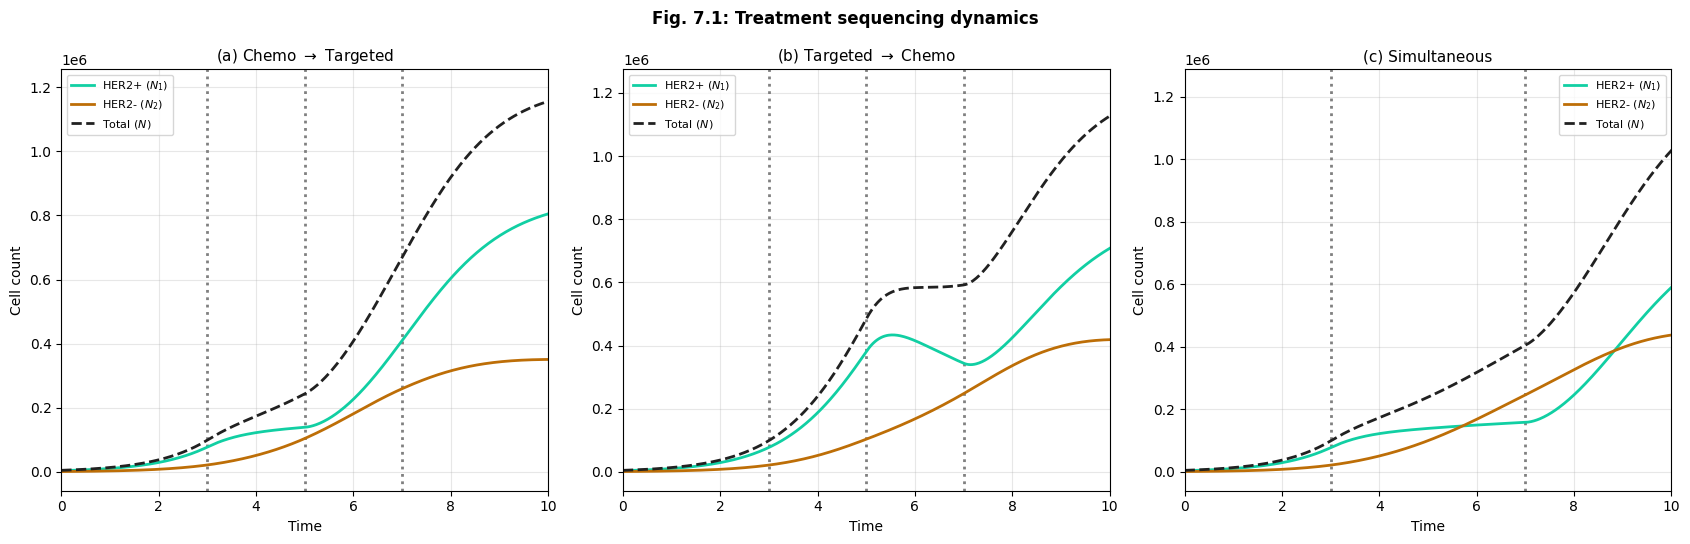

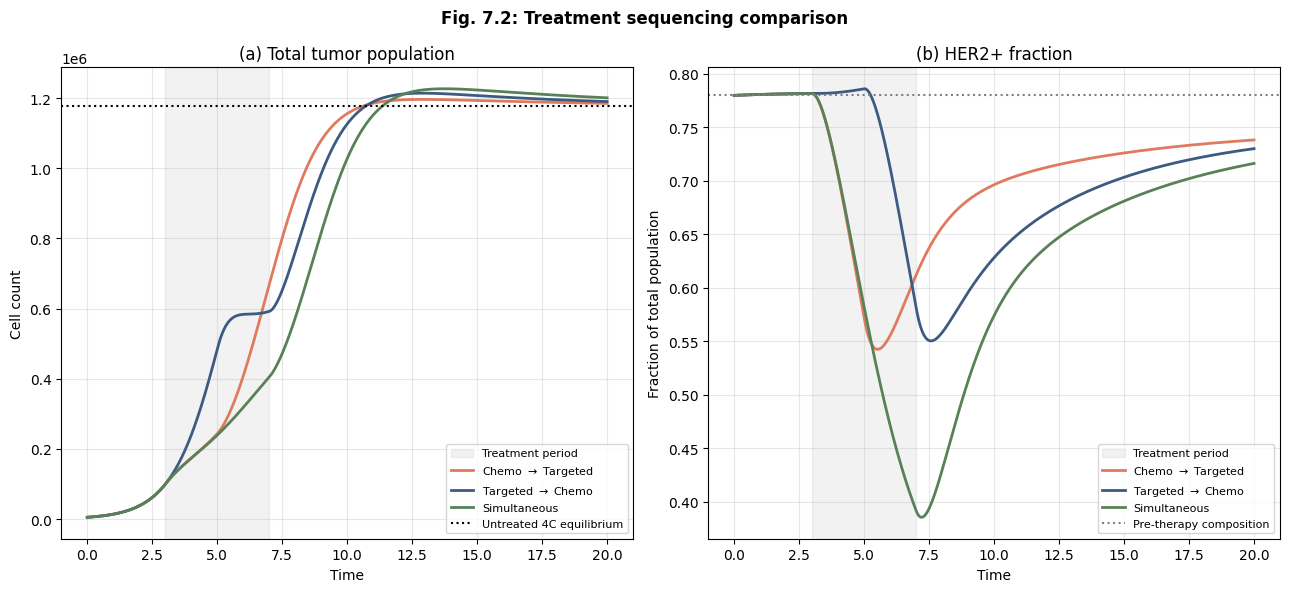

In [16]:
# --- Chapter 7. Treatment Sequencing  ---
#Fig. 9: Treatment sequencing dynamics
fig9, axes9 = plt.subplots(1, 3, figsize=(17, 5.5))
fig9.suptitle('Fig. 7.1: Treatment sequencing dynamics', fontsize=12, fontweight='bold')
schedules = [('(a) Chemo $\\rightarrow$ Targeted', sol_chemo_targeted, N1_chemo_targeted, N2_chemo_targeted,
     N_total_chemo_targeted, (3, 5, 7)),
    ('(b) Targeted $\\rightarrow$ Chemo', sol_targeted_chemo, N1_targeted_chemo, N2_targeted_chemo,
     N_total_targeted_chemo, (3, 5, 7)),
    ('(c) Simultaneous', sol_simultaneous, N1_simultaneous, N2_simultaneous,
     N_total_simultaneous, (3, 7)),]
for ax, (title, sol, N1, N2, Ntot, tlines) in zip(axes9, schedules):
    for tline in tlines: ax.axvline(tline, color='gray', ls=':', lw=2)
    ax.plot(sol.t, N1, color=colN1, lw=2, label='HER2+ ($N_1$)')
    ax.plot(sol.t, N2, color=colN2, lw=2, label='HER2- ($N_2$)')
    ax.plot(sol.t, Ntot, color=colTot, lw=2, ls='--', label='Total ($N$)')
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, 10)
    ax.set_xlabel('Time')
    ax.set_ylabel('Cell count')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Fig. 10: Treatment sequencing comparison
colCT = '#E07A5F'   # chemo -> targeted
colTC = '#3D5A80'   # targeted -> chemo
colSIM = '#588157'  # simultaneous

fig10, axes10 = plt.subplots(1, 2, figsize=(13, 6))
fig10.suptitle('Fig. 7.2: Treatment sequencing comparison', fontsize=12, fontweight='bold', y=0.98)
ax = axes10[0]
ax.axvspan(3, 7, color='gray', alpha=0.10, label='Treatment period')
ax.plot(sol_chemo_targeted.t, N_total_chemo_targeted, color=colCT, lw=2, label='Chemo $\\rightarrow$ Targeted')
ax.plot(sol_targeted_chemo.t, N_total_targeted_chemo, color=colTC, lw=2, label='Targeted $\\rightarrow$ Chemo')
ax.plot(sol_simultaneous.t, N_total_simultaneous, color=colSIM, lw=2, label='Simultaneous')
ax.axhline(N1_star + N2_star, color='black', ls=':', lw=1.5, label='Untreated 4C equilibrium')
ax.set_title('(a) Total tumor population')
ax.set_xlabel('Time')
ax.set_ylabel('Cell count')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes10[1]
ax.axvspan(3, 7, color='gray', alpha=0.10, label='Treatment period')
ax.plot(sol_chemo_targeted.t, frac_HER2_pos_chemo_targeted, color=colCT, lw=2, label='Chemo $\\rightarrow$ Targeted')
ax.plot(sol_targeted_chemo.t, frac_HER2_pos_targeted_chemo, color=colTC, lw=2, label='Targeted $\\rightarrow$ Chemo')
ax.plot(sol_simultaneous.t, frac_HER2_pos_simultaneous, color=colSIM, lw=2, label='Simultaneous')
ax.axhline(0.78, color='gray', ls=':', lw=1.5, label='Pre-therapy composition')
ax.set_title('(b) HER2+ fraction')
ax.set_xlabel('Time')
ax.set_ylabel('Fraction of total population')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()